In [1]:
import pandas as pd

features = pd.read_csv("../data/features/match_features_multi_season.csv", parse_dates=["utcDate"])

home_features = features[features["is_home"] == True].copy()
away_features = features[features["is_home"] == False].copy()

In [2]:
# Prefix columns so we can tell home vs away stats apart after merging
feature_cols = ["rolling_form_pts", "win_streak", "loss_streak", "avg_goals_scored",
                 "avg_goals_conceded", "clean_sheet_pct", "days_since_last_match",
                 "home_win_pct", "away_win_pct", "h2h_win_pct"]

home_renamed = home_features[["match_id", "team", "result"] + feature_cols].add_prefix("home_")
home_renamed = home_renamed.rename(columns={"home_match_id": "match_id", "home_team": "home_team", "home_result": "home_result"})

away_renamed = away_features[["match_id", "team"] + feature_cols].add_prefix("away_")
away_renamed = away_renamed.rename(columns={"away_match_id": "match_id", "away_team": "away_team"})

In [3]:
match_level = home_renamed.merge(away_renamed, on="match_id")
print(match_level.shape)
match_level.head()

(1140, 24)


,match_id,home_team,home_result,home_rolling_form_pts,home_win_streak,home_loss_streak,home_avg_goals_scored,home_avg_goals_conceded,home_clean_sheet_pct,home_days_since_last_match,...,away_rolling_form_pts,away_win_streak,away_loss_streak,away_avg_goals_scored,away_avg_goals_conceded,away_clean_sheet_pct,away_days_since_last_match,away_home_win_pct,away_away_win_pct,away_h2h_win_pct
0,435945,AFC Bournemouth,DRAW,NaN,0,0,NaN,NaN,NaN,NaN,...,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,435963,AFC Bournemouth,LOSS,1.0,0,1,1.000000,2.000000,0.000000,6.0,...,4.0,1,0,2.000000,1.00,0.500000,6.0,NaN,0.00,NaN
2,435983,AFC Bournemouth,DRAW,2.0,0,0,1.000000,2.000000,0.000000,14.0,...,4.0,0,1,1.250000,1.25,0.250000,14.0,NaN,0.00,NaN
3,436003,AFC Bournemouth,LOSS,2.0,0,1,0.833333,1.833333,0.166667,6.0,...,11.0,0,0,1.833333,1.00,0.333333,6.0,NaN,1.00,NaN
4,436023,AFC Bournemouth,LOSS,2.0,0,3,0.625000,2.250000,0.125000,14.0,...,5.0,0,0,1.125000,1.75,0.125000,13.0,NaN,0.25,NaN


In [4]:
match_level["home_team"].value_counts().head()
match_level["away_team"].value_counts().head()

away_team
West Ham United FC            57
Tottenham Hotspur FC          57
Chelsea FC                    57
Arsenal FC                    57
Wolverhampton Wanderers FC    57
Name: count, dtype: int64

In [11]:
match_level = match_level.drop(columns=["home_away_win_pct", "away_home_win_pct"])

In [12]:
match_level = match_level.dropna(subset=[
    "home_rolling_form_pts", "away_rolling_form_pts",
    "home_avg_goals_scored", "away_avg_goals_scored"
])

In [13]:
match_level["home_h2h_win_pct"] = match_level["home_h2h_win_pct"].fillna(0.5)
match_level["away_h2h_win_pct"] = match_level["away_h2h_win_pct"].fillna(0.5)

In [15]:
result_map = {"LOSS": 0, "DRAW": 1, "WIN": 2}
match_level["target"] = match_level["home_result"].map(result_map)

match_level["target"].value_counts()

target
2    479
0    360
1    271
Name: count, dtype: int64

In [16]:
match_level = match_level.merge(
    features[["match_id", "utcDate"]].drop_duplicates(),
    on="match_id"
)
match_level = match_level.sort_values("utcDate").reset_index(drop=True)

split_index = int(len(match_level) * 0.8)
train = match_level.iloc[:split_index]
test = match_level.iloc[split_index:]

print(train.shape, test.shape)
print("Train date range:", train["utcDate"].min(), "to", train["utcDate"].max())
print("Test date range:", test["utcDate"].min(), "to", test["utcDate"].max())

(888, 22) (222, 22)
Train date range: 2023-08-18 18:45:00+00:00 to 2025-12-14 14:00:00+00:00
Test date range: 2025-12-14 16:30:00+00:00 to 2026-05-24 15:00:00+00:00


In [17]:
feature_columns = [col for col in match_level.columns if col not in
    ["match_id", "home_team", "away_team", "home_result", "utcDate", "target"]]

X_train = train[feature_columns]
y_train = train["target"]

X_test = test[feature_columns]
y_test = test["target"]

print(feature_columns)
print(X_train.shape, X_test.shape)

['home_rolling_form_pts', 'home_win_streak', 'home_loss_streak', 'home_avg_goals_scored', 'home_avg_goals_conceded', 'home_clean_sheet_pct', 'home_days_since_last_match', 'home_h2h_win_pct', 'away_rolling_form_pts', 'away_win_streak', 'away_loss_streak', 'away_avg_goals_scored', 'away_avg_goals_conceded', 'away_clean_sheet_pct', 'away_days_since_last_match', 'away_h2h_win_pct']
(888, 16) (222, 16)


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy: 0.42792792792792794
              precision    recall  f1-score   support

        LOSS       0.37      0.38      0.38        66
        DRAW       0.44      0.06      0.10        72
         WIN       0.45      0.79      0.57        84

    accuracy                           0.43       222
   macro avg       0.42      0.41      0.35       222
weighted avg       0.43      0.43      0.36       222



In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg_scaled = LogisticRegression(max_iter=1000)
log_reg_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = log_reg_scaled.predict(X_test_scaled)

print("Accuracy (scaled):", accuracy_score(y_test, y_pred_scaled))
print(classification_report(y_test, y_pred_scaled, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy (scaled): 0.4189189189189189
              precision    recall  f1-score   support

        LOSS       0.37      0.38      0.38        66
        DRAW       0.36      0.06      0.10        72
         WIN       0.44      0.76      0.56        84

    accuracy                           0.42       222
   macro avg       0.39      0.40      0.34       222
weighted avg       0.40      0.42      0.36       222



In [20]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy: 0.42342342342342343
              precision    recall  f1-score   support

        LOSS       0.39      0.41      0.40        66
        DRAW       0.00      0.00      0.00        72
         WIN       0.44      0.80      0.57        84

    accuracy                           0.42       222
   macro avg       0.28      0.40      0.32       222
weighted avg       0.28      0.42      0.33       222



c:\Users\JOVAN\pl-analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\JOVAN\pl-analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\JOVAN\pl-analytics\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [21]:
importances = pd.Series(rf.feature_importances_, index=feature_columns).sort_values(ascending=False)
importances

home_avg_goals_conceded       0.138249
home_avg_goals_scored         0.131420
away_avg_goals_conceded       0.102176
away_avg_goals_scored         0.095147
away_clean_sheet_pct          0.087219
home_clean_sheet_pct          0.084206
home_rolling_form_pts         0.069336
away_rolling_form_pts         0.052901
home_days_since_last_match    0.041285
away_days_since_last_match    0.040909
away_h2h_win_pct              0.038813
home_h2h_win_pct              0.036509
away_loss_streak              0.028261
home_loss_streak              0.020147
away_win_streak               0.018749
home_win_streak               0.014674
dtype: float64

In [22]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42, eval_metric="mlogloss")
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb, target_names=["LOSS", "DRAW", "WIN"]))

Accuracy: 0.3963963963963964
              precision    recall  f1-score   support

        LOSS       0.35      0.44      0.39        66
        DRAW       0.35      0.08      0.13        72
         WIN       0.43      0.63      0.51        84

    accuracy                           0.40       222
   macro avg       0.38      0.38      0.35       222
weighted avg       0.38      0.40      0.35       222



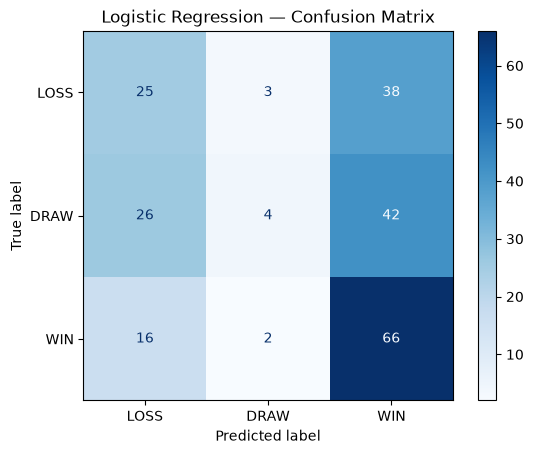

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["LOSS", "DRAW", "WIN"])
disp.plot(cmap="Blues")
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

In [24]:
import joblib
joblib.dump(log_reg, "../data/features/logistic_regression_model.pkl")

['../data/features/logistic_regression_model.pkl']

In [25]:
test_results = test[["match_id", "home_team", "away_team", "home_result"]].copy()
test_results["predicted_result"] = pd.Series(y_pred, index=test.index).map({0: "LOSS", 1: "DRAW", 2: "WIN"})
test_results.to_csv("../data/features/predictions.csv", index=False)